# Pérdida esperada: PD × LGD × EAD cuando las tres se mueven juntas

**Perfil:** Riesgo de crédito (productos)  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

¿Cuánta pérdida esperada se pierde al multiplicar PD, LGD y EAD *como si fueran independientes*, y qué corrección práctica la recupera? Después: ¿cómo cambia la provisión al pasar a un esquema de etapas tipo IFRS 9?

## Recorrido

1. Cartera sintética de cuatro productos con una pérdida esperada **verdadera** calculable por cuadratura.
2. **Versión 1:** la fórmula de libro, a nivel de crédito, con valores centrales.
3. **Diagnóstico:** descomposición del sesgo en covarianzas entre PD, LGD y EAD.
4. **Versión 2:** ajuste de ciclo bajo (*downturn*) y calibración del nivel de estrés implícito.
5. **Versión 3:** pérdida a 12 meses frente a toda la vida con etapas y umbral de deterioro significativo.
6. Robustez (muchas carteras), pruebas automáticas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy.stats import norm
from scipy.optimize import brentq
from numpy.polynomial.hermite_e import hermegauss

## 2. Un mundo donde el ciclo mueve PD, LGD y EAD a la vez

Hay un factor sistémico $y\sim N(0,1)$ (valores **negativos = recesión**). Para el crédito $i$:

- $\mathrm{PD}_i(y)=\Phi\!\Big(\dfrac{\Phi^{-1}(\mathrm{PD}_i)-\sqrt{\rho}\,y}{\sqrt{1-\rho}}\Big)$ (Vasicek; su media sobre $y$ es exactamente $\mathrm{PD}_i$).
- $\mathrm{LGD}_i(y)=\mathrm{LGD}_i\,(1-s_{L}\,y)$: sube en recesión (cae el valor de las garantías).
- $\mathrm{EAD}_i(y)=\mathrm{EAD}_i\,(1-s_{E}\,y)$: sube en recesión (los clientes de tarjeta usan más su cupo).

La pérdida esperada **verdadera** es $\mathrm{EL}=\mathbb{E}_y\big[\sum_i \mathrm{PD}_i(y)\,\mathrm{LGD}_i(y)\,\mathrm{EAD}_i(y)\big]$. Como la esperanza es sobre una normal estándar, se calcula con **cuadratura de Gauss-Hermite**, sin ruido de simulación.

In [2]:
PRODUCTOS = {
    #            pd    lgd   ead     rho   s_lgd s_ead  n
    "consumo":     dict(pd=0.060, lgd=0.65, ead=5_000,  rho=0.06, s_lgd=0.10, s_ead=0.02, n=3000),
    "tarjeta":     dict(pd=0.090, lgd=0.75, ead=3_000,  rho=0.08, s_lgd=0.08, s_ead=0.15, n=3000),
    "vehiculo":    dict(pd=0.030, lgd=0.40, ead=18_000, rho=0.08, s_lgd=0.20, s_ead=0.00, n=3000),
    "hipotecario": dict(pd=0.015, lgd=0.20, ead=90_000, rho=0.15, s_lgd=0.35, s_ead=0.00, n=3000),
}


def generar_cartera(seed=SEED):
    rng = np.random.default_rng(seed)
    filas = []
    for nombre, p in PRODUCTOS.items():
        n = p["n"]
        pd_i = rng.beta(p["pd"] * 40, (1 - p["pd"]) * 40, n)
        lgd_i = np.clip(rng.beta(p["lgd"] * 8, (1 - p["lgd"]) * 8, n), 0.02, 0.98)
        ead_i = rng.lognormal(np.log(p["ead"]), 0.4, n)
        filas.append(pd.DataFrame({"producto": nombre, "pd": pd_i, "lgd": lgd_i, "ead": ead_i,
                                   "rho": p["rho"], "s_lgd": p["s_lgd"], "s_ead": p["s_ead"]}))
    return pd.concat(filas, ignore_index=True)


cartera = generar_cartera()
print(cartera.shape)
cartera.groupby("producto")[["pd", "lgd", "ead"]].mean()

(12000, 7)


,pd,lgd,ead
producto,,,
consumo,0.0588,0.6503,"5,453.7488"
hipotecario,0.0145,0.1991,"98,351.5378"
tarjeta,0.0895,0.7579,"3,227.9185"
vehiculo,0.0305,0.4018,"19,425.0649"


### 2.1 La verdad por cuadratura, y su verificación por simulación

In [3]:
NODOS, PESOS = hermegauss(80)
PESOS = PESOS / PESOS.sum()          # pesos de la normal estandar


def perdida_condicional(d, y):
    # perdida esperada del grupo d dado el factor y (los incumplimientos son independientes dado y)
    pd_y = norm.cdf((norm.ppf(d["pd"].to_numpy()) - np.sqrt(d["rho"].to_numpy()) * y) / np.sqrt(1 - d["rho"].to_numpy()))
    lgd_y = np.clip(d["lgd"].to_numpy() * (1 - d["s_lgd"].to_numpy() * y), 0, 1)
    ead_y = np.maximum(d["ead"].to_numpy() * (1 - d["s_ead"].to_numpy() * y), 0)
    return pd_y * lgd_y * ead_y


def el_verdadera(d):
    return float(sum(w * perdida_condicional(d, y).sum() for y, w in zip(NODOS, PESOS)))


def el_v1(d):
    return float((d["pd"] * d["lgd"] * d["ead"]).sum())


# verificacion independiente: Monte Carlo sobre y
rng = np.random.default_rng(1)
ys = rng.standard_normal(4000)
d0 = cartera[cartera["producto"] == "tarjeta"]
mc = np.array([perdida_condicional(d0, y).sum() for y in ys])
print(f"tarjeta  cuadratura = {el_verdadera(d0):,.0f}   Monte Carlo = {mc.mean():,.0f}  (error estandar {mc.std() / np.sqrt(len(mc)):,.0f})")
assert abs(el_verdadera(d0) - mc.mean()) < 4 * mc.std() / np.sqrt(len(mc))

tarjeta  cuadratura = 736,803   Monte Carlo = 742,269  (error estandar 8,661)


## 3. Versión 1: la fórmula de libro

$\mathrm{EL}_{v1}=\sum_i \mathrm{PD}_i\,\mathrm{LGD}_i\,\mathrm{EAD}_i$. Es lo que haría cualquiera con la hoja de cálculo.

In [4]:
filas = []
for prod, d in cartera.groupby("producto"):
    v, t = el_v1(d), el_verdadera(d)
    filas.append({"producto": prod, "exposicion": d["ead"].sum(), "EL_v1": v, "EL_verdadera": t,
                  "sesgo_%": (v / t - 1) * 100, "EL_v1/exposicion_%": v / d["ead"].sum() * 100,
                  "EL_verdadera/exposicion_%": t / d["ead"].sum() * 100})
res1 = pd.DataFrame(filas).set_index("producto")
tot = {"exposicion": res1["exposicion"].sum(), "EL_v1": res1["EL_v1"].sum(), "EL_verdadera": res1["EL_verdadera"].sum()}
tot["sesgo_%"] = (tot["EL_v1"] / tot["EL_verdadera"] - 1) * 100
res1.loc["TOTAL"] = {**tot, "EL_v1/exposicion_%": tot["EL_v1"] / tot["exposicion"] * 100,
                     "EL_verdadera/exposicion_%": tot["EL_verdadera"] / tot["exposicion"] * 100}
res1.round(3)

,exposicion,EL_v1,EL_verdadera,sesgo_%,EL_v1/exposicion_%,EL_verdadera/exposicion_%
producto,,,,,,
consumo,"16,361,246.3520","627,489.3950","662,661.1290",-5.3080,3.8350,4.0500
hipotecario,"295,054,613.3430","840,467.3750","1,099,093.5640",-23.5310,0.2850,0.3730
tarjeta,"9,683,755.5260","657,164.9410","736,802.9770",-10.8090,6.7860,7.6090
vehiculo,"58,275,194.5990","720,999.8190","805,813.6970",-10.5250,1.2370,1.3830
TOTAL,"379,374,809.8190","2,846,121.5300","3,304,371.3670",-13.8680,0.7500,0.8710


In [5]:
print("Lectura:")
for prod in PRODUCTOS:
    print(f"  {prod:12s} la formula de libro subestima la perdida esperada en {-res1.loc[prod, 'sesgo_%']:.1f}%")
print(f"  Cartera total: subestimacion de {-res1.loc['TOTAL', 'sesgo_%']:.1f}%  ({res1.loc['TOTAL', 'EL_verdadera'] - res1.loc['TOTAL', 'EL_v1']:,.0f} de perdida esperada no provisionada)")

Lectura:
  consumo      la formula de libro subestima la perdida esperada en 5.3%
  tarjeta      la formula de libro subestima la perdida esperada en 10.8%
  vehiculo     la formula de libro subestima la perdida esperada en 10.5%
  hipotecario  la formula de libro subestima la perdida esperada en 23.5%
  Cartera total: subestimacion de 13.9%  (458,250 de perdida esperada no provisionada)


## 4. Diagnóstico: ¿de dónde sale el sesgo?

Para tres variables aleatorias $\mathbb{E}[XYZ]=\mathbb{E}X\,\mathbb{E}Y\,\mathbb{E}Z+\text{(covarianzas)}$. Aquí las covarianzas existen porque las tres dependen de $y$. Se puede **descomponer el sesgo por fuente** apagando mecanismos de uno en uno: si $s_L=0$ queda solo la correlación PD–EAD, etc.

In [6]:
def el_con(d, s_lgd=None, s_ead=None, rho=None):
    d = d.copy()
    if s_lgd is not None: d["s_lgd"] = s_lgd
    if s_ead is not None: d["s_ead"] = s_ead
    if rho is not None: d["rho"] = rho
    return el_verdadera(d)

filas = []
for prod, d in cartera.groupby("producto"):
    base = el_v1(d)
    solo_pd = el_con(d, s_lgd=0.0, s_ead=0.0)                     # el factor mueve solo la PD
    pd_lgd = el_con(d, s_ead=0.0)
    pd_ead = el_con(d, s_lgd=0.0)
    todo = el_verdadera(d)
    filas.append({"producto": prod, "base_(v1)": base, "efecto_solo_PD": solo_pd - base,
                  "efecto_LGD_sobre_PD": pd_lgd - solo_pd, "efecto_EAD_sobre_PD": pd_ead - solo_pd,
                  "total": todo - base})
desc = pd.DataFrame(filas).set_index("producto")
desc["total_%_de_base"] = desc["total"] / desc["base_(v1)"] * 100
desc.round(2)

,base_(v1),efecto_solo_PD,efecto_LGD_sobre_PD,efecto_EAD_sobre_PD,total,total_%_de_base
producto,,,,,,
consumo,"627,489.3900",0.0000,"27,920.3900","5,837.9500","35,171.7300",5.6100
hipotecario,"840,467.3800",-0.0000,"258,626.1900",0.0000,"258,626.1900",30.7700
tarjeta,"657,164.9400",0.0000,"22,671.8800","48,587.8600","79,638.0400",12.1200
vehiculo,"720,999.8200",-0.0000,"84,813.8800",0.0000,"84,813.8800",11.7600


In [7]:
print("Lectura:")
for prod, f in desc.iterrows():
    fuentes = {"PD sola": f["efecto_solo_PD"], "LGD x PD": f["efecto_LGD_sobre_PD"], "EAD x PD": f["efecto_EAD_sobre_PD"]}
    mayor = max(fuentes, key=lambda k: abs(fuentes[k]))
    print(f"  {prod:12s} el mayor aporte al sesgo viene de: {mayor}")
# por que 'PD sola' ya es ~0: E_y[PD(y)] = PD (identidad de Vasicek)
d_ = cartera[cartera['producto'] == 'consumo']
print(f"\nVerificacion: con LGD y EAD constantes, la EL verdadera iguala a v1 (identidad de Vasicek): {el_con(d_, s_lgd=0.0, s_ead=0.0) / el_v1(d_) - 1:+.2e}")

Lectura:
  consumo      el mayor aporte al sesgo viene de: LGD x PD
  hipotecario  el mayor aporte al sesgo viene de: LGD x PD
  tarjeta      el mayor aporte al sesgo viene de: EAD x PD
  vehiculo     el mayor aporte al sesgo viene de: LGD x PD

Verificacion: con LGD y EAD constantes, la EL verdadera iguala a v1 (identidad de Vasicek): +0.00e+00


**Qué se aprende.** Mover solo la PD con el ciclo **no** crea sesgo: la esperanza de la PD condicional es la PD incondicional. El sesgo aparece cuando LGD y EAD se mueven **junto con** la PD (riesgo de correlación adversa, *wrong-way risk*). Por eso importa más en hipotecario/vehículo (garantías que se deprecian) y tarjeta (cupo que se usa más en recesión).

## 5. Versión 2: ajuste de ciclo bajo (*downturn*)

La práctica habitual no es modelar el factor completo sino usar LGD y EAD **de ciclo bajo**: valores evaluados en un nivel de estrés $y^*<0$, con la PD sin ajustar:

$$\mathrm{EL}_{v2}(y^*)=\sum_i \mathrm{PD}_i\,\mathrm{LGD}_i(y^*)\,\mathrm{EAD}_i(y^*).$$

Pregunta útil: **¿qué nivel de estrés $y^*$ iguala la pérdida verdadera?** Es el "ciclo bajo implícito" de cada producto.

In [8]:
def el_v2(d, ystar):
    lgd = np.clip(d["lgd"] * (1 - d["s_lgd"] * ystar), 0, 1)
    ead = np.maximum(d["ead"] * (1 - d["s_ead"] * ystar), 0)
    return float((d["pd"] * lgd * ead).sum())


filas = []
for prod, d in cartera.groupby("producto"):
    t = el_verdadera(d)
    ystar = brentq(lambda y: el_v2(d, y) - t, -6, 6)
    filas.append({"producto": prod, "y_estrella_implicito": ystar, "percentil_del_ciclo": norm.cdf(ystar) * 100,
                  "EL_v2_en_y*": el_v2(d, ystar), "EL_verdadera": t})
res2 = pd.DataFrame(filas).set_index("producto")
res2.round(4)

,y_estrella_implicito,percentil_del_ciclo,EL_v2_en_y*,EL_verdadera
producto,,,,
consumo,-0.4639,32.1360,"662,661.1293","662,661.1293"
hipotecario,-0.8792,18.9645,"1,099,093.5641","1,099,093.5641"
tarjeta,-0.5159,30.2979,"736,802.9765","736,802.9765"
vehiculo,-0.5884,27.8127,"805,813.6972","805,813.6972"


In [9]:
print("Lectura:")
for prod, f in res2.iterrows():
    print(f"  {prod:12s} el ciclo bajo implicito esta en y*={f['y_estrella_implicito']:+.2f} (percentil {f['percentil_del_ciclo']:.0f} del ciclo)")
rango = res2["y_estrella_implicito"]
print(f"\nLos y* implicitos van de {rango.min():+.2f} ({rango.idxmin()}) a {rango.max():+.2f} ({rango.idxmax()}): no hay un estres unico que calce a todos.")
print("Error de usar un estres fijo para todos los productos:")
for ys_ in (-0.5, -1.0, -2.0):
    err = {prod: el_v2(d, ys_) / el_verdadera(d) - 1 for prod, d in cartera.groupby("producto")}
    print(f"  y*={ys_:+.1f}: " + ", ".join(f"{k} {v:+.1%}" for k, v in err.items()))

Lectura:
  consumo      el ciclo bajo implicito esta en y*=-0.46 (percentil 32 del ciclo)
  hipotecario  el ciclo bajo implicito esta en y*=-0.88 (percentil 19 del ciclo)
  tarjeta      el ciclo bajo implicito esta en y*=-0.52 (percentil 30 del ciclo)
  vehiculo     el ciclo bajo implicito esta en y*=-0.59 (percentil 28 del ciclo)

Los y* implicitos van de -0.88 (hipotecario) a -0.46 (consumo): no hay un estres unico que calce a todos.
Error de usar un estres fijo para todos los productos:


  y*=-0.5: consumo +0.4%, hipotecario -10.1%, tarjeta -0.3%, vehiculo -1.6%


  y*=-1.0: consumo +6.2%, hipotecario +3.2%, tarjeta +10.4%, vehiculo +7.3%


  y*=-2.0: consumo +17.2%, hipotecario +29.7%, tarjeta +31.9%, vehiculo +24.7%


No existe un único $y^*$ que deje a todos los productos en cero: los niveles implícitos van de −0,46 (consumo) a −0,88 (hipotecario). Con $y^*=-0{,}5$ la hipoteca queda ~10 % corta mientras los demás casi calzan; con $y^*=-1$ y $y^*=-2$ **todos** sobre-provisionan, y más cuanto más sensible es el producto. La calibración por producto es más defendible, pero exige series largas con al menos un ciclo completo; ese es el límite real de este enfoque.

## 6. Versión 3: de 12 meses a toda la vida (IFRS 9 simplificado)

- **Etapa 1:** pérdida esperada a **12 meses**.
- **Etapa 2** (aumento significativo del riesgo, SICR): pérdida esperada a **toda la vida** del crédito.

Para cada crédito con plazo $T$ años y PD a 12 meses constante (riesgo instantáneo constante $h=-\ln(1-\mathrm{PD}_{12})$), con amortización lineal de la exposición y descuento a tasa $r$:

$$\mathrm{EL}_{vida}=\sum_{t=1}^{T}S(t-1)\,\big(1-e^{-h}\big)\,\mathrm{LGD}\,\mathrm{EAD}_t\,(1+r)^{-(t-0.5)}.$$

In [10]:
def el_vida(pd12, lgd, ead0, T, r=0.10):
    h = -np.log1p(-np.clip(pd12, 0, 0.999))
    total = np.zeros_like(pd12, dtype=float)
    for t in range(1, int(T.max()) + 1):
        vivo = (T >= t)
        s_prev = np.exp(-h * (t - 1))
        pd_marg = s_prev * (1 - np.exp(-h))
        ead_t = ead0 * np.clip(1 - (t - 1) / T, 0, 1)
        total += vivo * pd_marg * lgd * ead_t / (1 + r) ** (t - 0.5)
    return total


rng = np.random.default_rng(7)
d = cartera.copy()
d["plazo"] = d["producto"].map({"consumo": 3, "tarjeta": 2, "vehiculo": 5, "hipotecario": 15}).to_numpy()
d["pd_orig"] = d["pd"] * np.exp(rng.normal(-0.15, 0.35, len(d)))      # PD al originar
d["razon_pd"] = d["pd"] / d["pd_orig"]                                 # deterioro desde el origen
d["el_12m"] = el_vida(d["pd"].to_numpy(), d["lgd"].to_numpy(), d["ead"].to_numpy(), np.ones(len(d)))
d["el_vida"] = el_vida(d["pd"].to_numpy(), d["lgd"].to_numpy(), d["ead"].to_numpy(), d["plazo"].to_numpy())
print(d.groupby("producto")[["el_12m", "el_vida"]].sum().assign(cociente=lambda t: t["el_vida"] / t["el_12m"]).round(2))

                  el_12m        el_vida  cociente
producto                                         
consumo     598,287.6600 1,070,398.8400    1.7900
hipotecario 801,354.2000 3,837,163.5500    4.7900
tarjeta     626,582.1900   879,851.5900    1.4000
vehiculo    687,446.3500 1,718,836.2200    2.5000


In [11]:
def provision(d, umbral):
    etapa2 = d["razon_pd"] > umbral
    return float(np.where(etapa2, d["el_vida"], d["el_12m"]).sum()), float(etapa2.mean())

umbrales = [1.25, 1.5, 2.0, 2.5, 3.0, 4.0]
tabla = pd.DataFrame([{"umbral_SICR": u, "provision": provision(d, u)[0], "pct_en_etapa2": provision(d, u)[1] * 100} for u in umbrales])
tabla["vs_todo_12m_%"] = (tabla["provision"] / d["el_12m"].sum() - 1) * 100
print(f"Todo a 12 meses: {d['el_12m'].sum():,.0f} | todo a toda la vida: {d['el_vida'].sum():,.0f}")
tabla.round(2)

Todo a 12 meses: 2,713,670 | todo a toda la vida: 7,506,250


,umbral_SICR,provision,pct_en_etapa2,vs_todo_12m_%
0,1.2500,"4,716,204.2000",42.3900,73.7900
1,1.5000,"3,811,029.8700",23.3300,40.4400
2,2.0000,"2,972,844.5800",6.2200,9.5500
3,2.5000,"2,773,906.9100",1.4200,2.2200
4,3.0000,"2,723,366.3300",0.3000,0.3600
5,4.0000,"2,713,830.4800",0.0100,0.0100


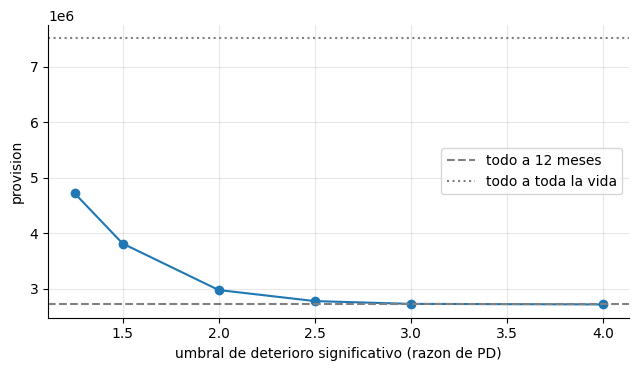

Lectura:
  Mover el umbral de SICR de 2.0x a 1.25x cambia la provision en +59%.
  Pasar de 12 meses a toda la vida multiplica la perdida esperada por 2.8x: el umbral es una decision de politica de gran impacto.


In [12]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(tabla["umbral_SICR"], tabla["provision"], "o-"); ax.axhline(d["el_12m"].sum(), ls="--", color="gray", label="todo a 12 meses")
ax.axhline(d["el_vida"].sum(), ls=":", color="gray", label="todo a toda la vida")
ax.set_xlabel("umbral de deterioro significativo (razon de PD)"); ax.set_ylabel("provision"); ax.legend(); plt.show()
print("Lectura:")
print(f"  Mover el umbral de SICR de 2.0x a 1.25x cambia la provision en {(tabla.loc[tabla.umbral_SICR==1.25,'provision'].iloc[0]/tabla.loc[tabla.umbral_SICR==2.0,'provision'].iloc[0]-1)*100:+.0f}%.")
print(f"  Pasar de 12 meses a toda la vida multiplica la perdida esperada por {d['el_vida'].sum()/d['el_12m'].sum():.1f}x: el umbral es una decision de politica de gran impacto.")

## 7. Robustez: ¿el sesgo es ruido de una cartera o es estructural?

Se repite el experimento con 40 carteras distintas (semillas diferentes). Si el sesgo de la versión 1 fuera ruido, cambiaría de signo; si es estructural, siempre irá en la misma dirección.

In [13]:
sesgos = []
for sd in range(40):
    c = generar_cartera(seed=100 + sd)
    sesgos.append(el_v1(c) / el_verdadera(c) - 1)
sesgos = np.array(sesgos)
print(f"Sesgo relativo de v1 en 40 carteras: media {sesgos.mean():.2%} | desvio {sesgos.std():.2%} | min {sesgos.min():.2%} | max {sesgos.max():.2%}")
print(f"Carteras en que v1 subestima: {(sesgos < 0).sum()} de {len(sesgos)}")

Sesgo relativo de v1 en 40 carteras: media -13.99% | desvio 0.09% | min -14.17% | max -13.82%
Carteras en que v1 subestima: 40 de 40


### 7.1 Sensibilidad a la correlación de activos $\rho$ y a la sensibilidad de LGD

In [14]:
filas = []
for s_l in (0.0, 0.1, 0.2, 0.4):
    for rho in (0.03, 0.08, 0.15, 0.25):
        c = cartera.copy(); c["s_lgd"] = s_l; c["rho"] = rho
        filas.append({"s_lgd": s_l, "rho": rho, "sesgo_v1_%": (el_v1(c) / el_verdadera(c) - 1) * 100})
sens = pd.DataFrame(filas).pivot(index="s_lgd", columns="rho", values="sesgo_v1_%")
sens.round(2)

rho,0.0300,0.0800,0.1500,0.2500
s_lgd,,,,
0.0000,-1.1800,-1.9100,-2.5900,-3.3200
0.1000,-4.6700,-7.2700,-9.6400,-12.0600
0.2000,-7.3100,-11.3700,-14.9100,-18.4000
0.4000,-10.8200,-17.0400,-22.1300,-26.8800


In [15]:
print("Lectura: el sesgo crece (en valor absoluto) con la sensibilidad de la LGD y con rho (mas correlacion, mas covarianza con la PD).")
print("Con s_lgd = 0 todavia queda sesgo porque la sensibilidad de EAD (tarjeta, consumo) sigue encendida:", sens.loc[0.0].round(2).tolist())
c0 = cartera.copy(); c0["s_lgd"] = 0.0; c0["s_ead"] = 0.0
nulo = []
for rho in (0.03, 0.08, 0.15, 0.25):
    c0["rho"] = rho
    nulo.append((el_v1(c0) / el_verdadera(c0) - 1) * 100)
print("Con s_lgd = 0 Y s_ead = 0 no hay mecanismo y el sesgo es nulo:", [f"{x:.1e}" for x in nulo])

Lectura: el sesgo crece (en valor absoluto) con la sensibilidad de la LGD y con rho (mas correlacion, mas covarianza con la PD).
Con s_lgd = 0 todavia queda sesgo porque la sensibilidad de EAD (tarjeta, consumo) sigue encendida: [-1.18, -1.91, -2.59, -3.32]


Con s_lgd = 0 Y s_ead = 0 no hay mecanismo y el sesgo es nulo: ['-1.1e-14', '-1.1e-14', '0.0e+00', '2.2e-14']


## 8. Pruebas automáticas

In [16]:
# 8.1 la cuadratura integra bien: pesos suman 1, integra la media y la varianza de N(0,1)
assert abs(PESOS.sum() - 1) < 1e-12
assert abs((PESOS * NODOS).sum()) < 1e-10 and abs((PESOS * NODOS ** 2).sum() - 1) < 1e-8
# 8.2 identidad de Vasicek: la PD condicional promedia a la PD incondicional
for rho in (0.05, 0.2):
    p0 = 0.03
    cond = norm.cdf((norm.ppf(p0) - np.sqrt(rho) * NODOS) / np.sqrt(1 - rho))
    assert abs((PESOS * cond).sum() - p0) < 1e-6
# 8.3 sin dependencia del ciclo en LGD y EAD, la verdad coincide con v1
for prod, dd in cartera.groupby("producto"):
    assert abs(el_con(dd, s_lgd=0.0, s_ead=0.0) / el_v1(dd) - 1) < 1e-5
# 8.4 la verdad es mayor que v1 cuando LGD y EAD suben en recesion (en todos los productos y carteras)
assert all(el_verdadera(dd) > el_v1(dd) for _, dd in cartera.groupby("producto"))
assert (sesgos < 0).all(), "v1 deberia subestimar en todas las carteras simuladas"
# 8.5 el estres implicito reproduce la perdida verdadera
for prod, f in res2.iterrows():
    dd = cartera[cartera["producto"] == prod]
    assert abs(el_v2(dd, f["y_estrella_implicito"]) / el_verdadera(dd) - 1) < 1e-6
# 8.6 IFRS 9: vida >= 12m; la provision por etapas esta entre ambos y decrece con el umbral
assert (d["el_vida"] >= d["el_12m"] - 1e-9).all()
assert d["el_12m"].sum() <= tabla["provision"].min() + 1e-6 and tabla["provision"].max() <= d["el_vida"].sum() + 1e-6
assert tabla["provision"].is_monotonic_decreasing
# 8.7 plazo de un ano: EL a toda la vida == EL a 12 meses
uno = np.ones(5)
esperado_1a = 0.05 * 0.5 * 100.0 / (1 + 0.10) ** 0.5            # pd12 * lgd * ead / (1+r)^0.5
assert np.allclose(el_vida(np.full(5, .05), np.full(5, .5), np.full(5, 100.), uno), esperado_1a), "a 1 ano la vida debe igualar la formula de 12 meses"
assert np.allclose(el_vida(np.zeros(3), np.full(3, .5), np.full(3, 100.), np.array([1, 2, 5])), 0), "PD cero implica EL cero"
# 8.8 la EL a toda la vida crece con el plazo
tt = el_vida(np.full(4, .05), np.full(4, .5), np.full(4, 100.), np.array([1, 2, 3, 5]))
assert np.all(np.diff(tt) > 0)
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| v1 (fórmula de libro) | Subestima la pérdida esperada en todos los productos y en las 40 carteras simuladas | No usarla sola cuando LGD/EAD dependen del ciclo |
| Diagnóstico | Mover solo la PD con el ciclo no crea sesgo (identidad de Vasicek); lo crean LGD y EAD correlacionadas con la PD | Buscar riesgo de correlación adversa por producto |
| v2 (ciclo bajo) | Cada producto exige un nivel de estrés implícito distinto; un único estrés fijo sobre/sub-provisiona | Calibrar por producto con ciclo completo |
| v3 (IFRS 9) | Pasar de 12 meses a vida completa multiplica la EL; el umbral de SICR mueve mucho la provisión | Tratar el umbral como decisión de política con análisis de sensibilidad |

**Límites que no deben ocultarse**

- Los parámetros de sensibilidad al ciclo ($s_L$, $s_E$) son **supuestos**; con datos reales se estimarían de series históricas de recuperaciones y uso de cupo.
- Un solo factor sistémico y PD de riesgo instantáneo constante: simplificaciones fuertes. IFRS 9 real exige escenarios macro ponderados y estructura temporal de PD.
- Las etapas aquí se asignan solo por razón de PD; en la práctica también intervienen mora > 30 días y criterios cualitativos.
- Los datos son sintéticos: los porcentajes de subestimación no son extrapolables a ninguna cartera real.